### Linear Regression
Car price prediction project

The dataset: data.csv from Kaggle

The project plan
We will do the project in several steps:

Get the data and do exploratory data analysis: just look at the data and try to learn more about it.
Prepare the dataset and train a linear regression model on it to predict the price of a car.
Go into the details of how linear regression is implemented — we will actually implement it ourselves.
Evaluate the quality of the model with RMSE. RMSE stands for root mean squared error, a metric for evaluating the quality of model predictions.
Do some feature engineering: the process of creating new features, new characteristics that we can use for our model.
Deal with numerical stability problems and see how to solve them with regularization.
Finally, use the model.

### Step 1: Data preparation

We take the car price dataset and prepare it for machine learning: we download it, load it with pandas, and make the column names and the string values consistent.

In [28]:
import pandas as pd

In [29]:
# Loading the dataset

df = pd.read_csv('data.csv')

In [30]:
df.sample(5)

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
1305,Suzuki,Aerio,2005,regular unleaded,155.0,4.0,AUTOMATIC,all wheel drive,4.0,NaN,Compact,Wagon,26,21,481,17349
7974,Audi,R8,2014,premium unleaded (required),430.0,8.0,AUTOMATED_MANUAL,all wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,23,14,3105,124000
5191,Pontiac,G6,2009,flex-fuel (unleaded/E85),219.0,6.0,AUTOMATIC,front wheel drive,4.0,Flex Fuel,Midsize,Sedan,26,17,210,24710
10032,Cadillac,STS,2011,regular unleaded,302.0,6.0,AUTOMATIC,rear wheel drive,4.0,"Luxury,Performance",Large,Sedan,27,18,1624,50820
6072,Volkswagen,Jetta SportWagen,2013,regular unleaded,170.0,5.0,MANUAL,front wheel drive,4.0,NaN,Compact,Wagon,33,23,873,20595


Making the column names consistent

Looking at the column names, there is some inconsistency. Sometimes there are uppercase letters (Make, Model), sometimes there are spaces (Engine Fuel Type), sometimes underscores (Driven_Wheels).

To keep life simple, let's clean the names: make everything lowercase and replace spaces with underscores.

In [31]:
# String operations on column names

df.columns.str.lower().str.replace(' ', '_')

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

In [32]:
# Write the result back to the columns attribute:

df.columns = df.columns.str.lower().str.replace(' ', '_')

The values have the same problem as the columns names: sometimes they are all caps (BMW, MANUAL), sometimes not. Let's normalize the string values the same way.

First we need to find out which columns are strings — we cannot apply string methods to numbers. For that we use the dtypes attribute. It tells us, for every column, what type it is:

In [34]:
# Finding the string columns

df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [40]:
# Selecting the string columns

df.dtypes[df.dtypes == 'object']

Series([], dtype: object)

Course material is outdated on this point. The course was written for pandas 1.x/2.x, where text columns had the object dtype. Pandas 3.0 stores text in a dedicated string type that displays as str.

In [43]:
# # Selecting the string columns

df.dtypes[df.dtypes == 'str']

make                 str
model                str
engine_fuel_type     str
transmission_type    str
driven_wheels        str
market_category      str
vehicle_size         str
vehicle_style        str
dtype: object

In [ ]:
#  Take the index of this series and convert it to a Python list. No particular reason, it just looks nicer:

df.dtypes[df.dtypes == 'str'].index

Index(['make', 'model', 'engine_fuel_type', 'transmission_type',
       'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style'],
      dtype='str')

In [48]:
# Python list

strings = list(df.dtypes[df.dtypes == 'str'].index)     # Or, df.select_dtypes(include='str').columns.tolist()
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

Normalizing the string values

Now that we have all the string column names, we loop over them and apply the same transformation we used for the column names: lowercase everything and replace spaces with underscores, writing the result back to the DataFrame:

In [49]:
# Normalizing the string values

for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

After the loop the data looks cleaner. Everything is lowercase, and spaces in values are replaced with underscores:
The dataset is prepared

In [50]:
df.sample(5)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
1830,volkswagen,beetle_convertible,2015,regular_unleaded,170.0,4.0,automatic,front_wheel_drive,2.0,NaN,compact,convertible,32,24,873,29595
2562,honda,civic,2015,regular_unleaded,143.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,36,28,2202,18290
653,bmw,6_series,2015,premium_unleaded_(required),445.0,8.0,automatic,all_wheel_drive,2.0,"luxury,high-performance",midsize,convertible,24,16,3916,97900
10385,hyundai,tiburon,2006,regular_unleaded,138.0,4.0,automatic,front_wheel_drive,2.0,hatchback,compact,2dr_hatchback,27,19,1439,17095
5969,lexus,is_250,2013,premium_unleaded_(required),204.0,6.0,automatic,all_wheel_drive,4.0,luxury,midsize,sedan,27,21,454,37525


### Step 2: Exploratory data analysis

We do exploratory data analysis (EDA): we look at every column, see what kind of values are there, and try to get a feeling for the data and the problem before training a model.

2a. Looking at every column

We already know that some columns are strings and some are numbers. To see what is inside each of them, we iterate over all columns and print some statistics for every one: the column name, a few values, and the number of unique values:

In [ ]:
# Checking the unique values in each column

for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()         # an empty print = blank line

make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48

model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
<StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5

driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-pe

Walking through the output: make is the manufacturer of a car — BMW, Audi, Fiat, Mercedes-Benz, Chrysler, 48 of them in total. Model is more granular: every manufacturer has multiple models, which is why there are 914 unique values. Year is a numerical column with 28 different years. Engine fuel type is the type of fuel the engine gets — diesel and others, ten types in total. Engine horsepower says how powerful the engine is, and then we have the number of cylinders, the transmission type, the driven wheels, the market category, the vehicle size and style — all the characteristics we potentially know about a car.

Highway mpg is how many miles the car can drive on a highway per gallon of fuel, and city mpg is the same in the city. Popularity is something the authors of the dataset computed: they looked at Twitter and counted how many mentions a car had — the idea is that a more popular car has more mentions. And finally MSRP: the price of a car. This is what we want to predict, and of course there are many different values there.

2b. Now, we look at the distribution of price

The price column deserves a closer look. Looking at numbers is not very informative — we don't see the big picture. So we visualize it.

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


<Axes: xlabel='msrp', ylabel='Count'>

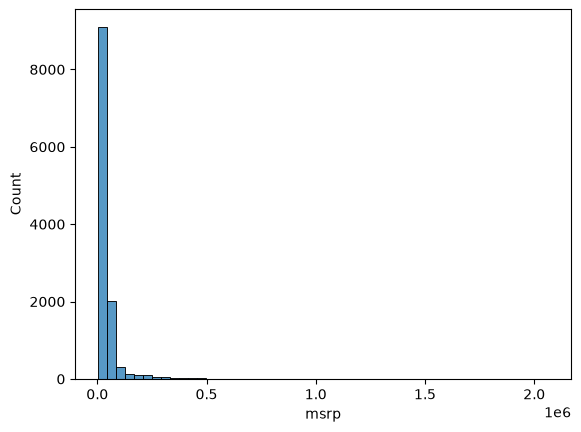

In [64]:
# 

sns.histplot(df.msrp, bins=50)

What we see is that a lot of prices are pretty cheap — most of the cars are concentrated on the left. Then there are very few cars that are super expensive: maybe one car costs 2 million, one costs 1.5 million, and a few cost around a million.

To see the shape better, we zoom in on prices below 100,000

<Axes: xlabel='msrp', ylabel='Count'>

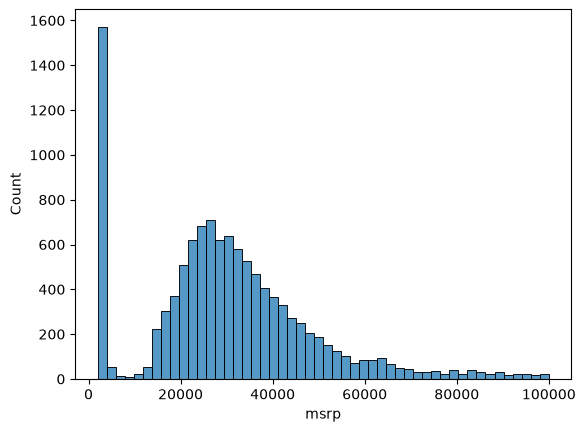

In [69]:
# Checking the distribution of MSRP values

sns.histplot(df.msrp[df.msrp < 100000], bins=50)

There is a strange peak of cars that cost 1,000 — probably the minimal price possible to put on the platform, which is why a bunch of cars cost exactly that. Then the number of cars slowly grows up to around 25,000 — about 700 cars cost that much — and after that it goes down as the price grows. Except for that peak at 1,000, this is a pretty reasonable distribution to expect for prices.

2c. Removing the long tail with a logarithm

While this distribution is not unexpected, it is not really good for machine learning: the long tail will confuse the model and screw things up. We want to get rid of it, and the usual trick is to apply the logarithm to the price.

The logarithm compresses large values. For large numbers, the value of the logarithm is not that large: going from 10 to 1,000 is a big jump, but the increase between their logarithms is not that high. So the logarithm takes very high values and makes them lower.

There is one problem with the plain logarithm: the logarithm of zero doesn't exist. If there is a zero in the data, numpy complains — it returns negative infinity and prints a warning:

In [ ]:
# Logarithmic Transformation

import numpy as np
np.log([0, 1, 1000, 5, 100])

C:\Users\dell\AppData\Local\Temp\ipykernel_31664\431590554.py:4: RuntimeWarning: divide by zero encountered in log
  np.log([0, 1, 1000, 5, 100])


array([      -inf, 0.        , 6.90775528, 1.60943791, 4.60517019])

In [74]:
# Instead, we can use the numpy function log1p, which calculates log(1+x). This way, we can avoid the problem with zero values.

np.log([1+0, 1+1, 1+1000, 1+5, 1+100])

array([0.        , 0.69314718, 6.90875478, 1.79175947, 4.61512052])

RuntimeWarning error gone because of log(1+x)

Now, using the numpy function log1p

In [73]:
# Checking the output of log1p with the original values

np.log1p([0, 1, 1000, 5, 100])

array([0.        , 0.69314718, 6.90875478, 1.79175947, 4.61512052])

Now, we apply the log1p to the price column. Let's apply it to the prices and call the result price_logs

In [75]:
# Applying log1p to the MSRP column

price_logs = np.log1p(df.msrp)

2d. Plotting the distribution of log-transformed prices


<Axes: xlabel='msrp', ylabel='Count'>

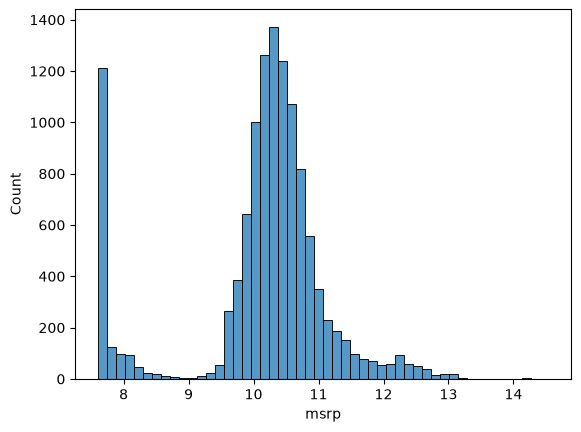

In [77]:
# Plotting the distribution of log-transformed prices

sns.histplot(price_logs, bins=50)

The tail is gone. All the large prices collapsed into a small area on the right, and the cars for usual consumers are still concentrated around the center. The shape now resembles a bell curve: a clear center of the distribution that goes down on both the left and the right side. This is called a normal distribution. (We still have that weird peak at 1,000, but apart from it, it looks close to normal.)

This situation is ideal for models: models do much better when the target variable looks like a normal distribution than with long-tail ones. That is why we typically want to get rid of long tails, and applying the logarithm to the price, like we just did, is one way of doing it.

2e. Missing values

To count how many missing values there are, we use isnull(): for every cell it says whether the value in this cell is missing or not. In this form it is not super useful, so we follow it with sum(), which sums across every column and tells us the number of missing values in each:

In [81]:
#

df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

We need to keep this in mind: before training the model, we will need to do something with these missing values.

### Step 3: Setting up the validation framework
The dataset is cleaned and explored, so now we set up the validation framework: we split the data into train, validation and test parts, and prepare the target variable for each part. We do it manually, with plain pandas and NumPy.

3a. Train, validation and test

To do it, we take our dataset and split it into three parts. The first part we use for training, the second one for validation, and the last one for testing. We train a model, check if it works fine on the validation dataset, and leave the test dataset alone: we use it only very occasionally, at the very end, to check that our model is doing good.

Then, from each of these parts we create a feature matrix X and the target variable y:

In [85]:
df.shape        # print(len(df)) also works

(11914, 16)

3b. Calculating the sizes of the parts

We will do a 60/20/20 split, so we first need to calculate how many records 20% actually is. Our dataframe has almost 12,000 records, so 20% of that is approximately 2,400. We want a whole number of records, not a fraction like 2382.8, so we cut the fraction off with int():

In [86]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

print(n, n_val, n_test, n_train)

11914 2382 2382 7150


Ideally we would write n_train = int(n * 0.6) as well, but because of rounding, the three parts may stop adding up to n - and we would accidentally leave a few records out. So instead, we take validation and test out first, and whatever remains goes to training. n_train is calculated as “whatever is left” rather than int(n * 0.6) so the three sizes always add up to exactly n, with no rows lost to rounding.

3c. Taking a part of the dataframe with iloc

Now we know the sizes, and we need to take a part of the dataframe of that size. For that we use iloc

In [88]:
# Getting the corresponding dataframe from the numbers

df_val = df.iloc[:n_val]
df_test = df.iloc[n_val:n_val+n_test]
df_train = df.iloc[n_val+n_test:]

df_val, df_test, df_train

(         make       model  year             engine_fuel_type  engine_hp  \
 0         bmw  1_series_m  2011  premium_unleaded_(required)      335.0   
 1         bmw    1_series  2011  premium_unleaded_(required)      300.0   
 2         bmw    1_series  2011  premium_unleaded_(required)      300.0   
 3         bmw    1_series  2011  premium_unleaded_(required)      230.0   
 4         bmw    1_series  2011  premium_unleaded_(required)      230.0   
 ...       ...         ...   ...                          ...        ...   
 2377  porsche     cayenne  2016  premium_unleaded_(required)      570.0   
 2378  porsche     cayenne  2016                       diesel      240.0   
 2379  porsche     cayenne  2017  premium_unleaded_(required)      520.0   
 2380  porsche     cayenne  2017  premium_unleaded_(required)      300.0   
 2381  porsche     cayenne  2017  premium_unleaded_(required)      440.0   
 
       engine_cylinders transmission_type     driven_wheels  number_of_doors  \
 0    

There is a problem here, though: the split is sequential. In our dataset the cars are ordered by make, so validation now contains all the BMWs at the beginning and all the Porsches at the end, and there are no BMWs in train at all:

We see that there is some order in this dataset, and we need to break it. In general it is always a good idea to shuffle the data: if there is some accidental order in it, we want to make sure it does not affect the split.

3d. Shuffling the records

In iloc we can pass an arbitrary sequence of numbers, and it will return the rows in that order. So we can take the numbers from 0 to n-1, reshuffle them, and then take the first 20% of the shuffled numbers for validation, the next 20% for test, and the rest for train:

To generate the sequence of numbers we use np.arange from NumPy, and to shuffle it we use np.random.shuffle:

In [91]:
# Setting the reshuffle

np.random.seed(2)       # for reproducibility, we set a random seed before shuffling

idx = np.arange(n)
np.random.shuffle(idx)      # it works in place, so we don’t write idx = np.random.shuffle(idx). That would set idx to None, since shuffle returns nothing.

3e. Now, we we index the dataframe with the shuffled numbers instead of the sequential ranges:

In [92]:
# We start with df_train here

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

3f. Resetting the index

After splitting, the rows keep their original index labels, so we reset them to be in order.

In [95]:
# checking the lengths of the three dataframes:

len(df_train), len(df_val), len(df_test)

# check a df to see the index

df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
434,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916,54900
1902,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873,29215
9334,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549,34675
5284,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86,303300


The index now contains the original row numbers - 2735, 6720 and so on, in random order. Sometimes it is inconvenient: we don't really need to know what the original index of each record was. So we reset the index and reassign the result back to the dataframe. We pass drop=True because we don't need the old index as a column:

In [96]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [ ]:
# confirm the index now goes from 0,1,2,...

df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916,54900
7146,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873,29215
7147,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549,34675
7148,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86,303300


3g. Preparing y and removing msrp

The dataframes will be used to make the feature matrix X. The target y comes from the msrp column.
 We already know that we need to apply the log1p transformation to it because of the long tail in its distribution. 
 Instead of keeping a pandas series, we immediately take its values with .values to get a NumPy array - we don't need the indexes and other pandas things for y:

In [100]:
# getting the y column

y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

# check y
y_train


array([ 9.57574708,  9.887663  ,  9.89323518, ..., 10.45380308,
       12.62248099, 10.54061978], shape=(7150,))

The last thing we need to do is remove msrp from the dataframes, for which we use the del operator:

In [103]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

Data Leakage

We delete it because we might accidentally use it. If the price gets into the features, we will use the price to predict the price - and of course the model will be perfect. 

If the price stayed inside X, the model would be given the answer as one of the inputs. It would learn “price = the msrp column”, get near-perfect scores, and be useless in real life, because when a new car arrives, its price is exactly what you don’t know. This mistake is called data leakage, and it’s one of the most common and serious errors in ML. Then we might spend a lot of time figuring out what is wrong.
That is the whole validation framework. We implemented it manually, without any library - just plain pandas and NumPy. We saw how to split the dataset into three parts, and now we are ready to move to the training part:

### Step 4

Linear regression
We derive the formula, implement it in Python for one car, and see what the prediction is made of.

The formula for one car: g(X) ≈ y

We take just three of the features of a row(1 car): engine horsepower, city miles per gallon and popularity:

In [104]:
# one car features

xi = [453, 11, 86]

In [105]:
# implementing the formular with code

xi = [453, 11, 86]      
w0 = 7.17       # bias, the starting value
w = [0.01, 0.04, 0.002]         # the weight the model learned, these values were given in the course

In [106]:
# linear regression function for one car(row)

def linear_regression(xi):
    n = len(xi)

    pred = w0

    for j in range(n):
        pred += w[j] * xi[j]

    return pred

In [107]:
# test the function

linear_regression(xi)

12.312

We start with the bias term, 7.17. This is what we predict for an average car if we don't know anything about it.
Then we know the car has 453 horsepower. Each horsepower adds 0.01 to the prediction: if the car had only one horsepower, the price would be higher by 0.01, and for 100 horsepower it's higher by 1. The more horsepower the engine has, the more expensive the car becomes - that's logical.
The next feature is miles per gallon in the city, with weight 0.04. The more fuel the car consumes in the city, the more expensive it is. This can make sense: cars that consume more fuel are probably fancier.
The last one is popularity, the number of mentions on Twitter, with a pretty low weight of 0.002. It doesn't seem to affect the price much: a lot of people would need to mention a car for this term to matter.

From log price back to dollars

To undo the logarithm we need the exponent. And there is a shortcut: np.expm1 is the inverse of np.log1p - apply one after the other and you are back where you started:

In [108]:
# log to original to get the price

np.expm1(12.312)

np.float64(222347.2221101062)

In [109]:
np.log1p(222347.2221101062)

np.float64(12.312)

So our prediction for this car is about 222,000 dollars. 